# Análisis exploratorio de usuarios de una plataforma educativa

## Notebook de repaso

Trabajaremos con información de usuarios de una plataforma de cursos online. El recorrido tiene tres etapas:

1. **Análisis Exploratorio de Datos (EDA)**
2. **Transformación y limpieza de datos**
3. **Introducción a Feature Engineering**


## Objetivos de la clase

- reconocer la estructura y el significado de un dataset;
- diferenciar variables numéricas, categóricas, temporales e identificadores;
- detectar faltantes, duplicados, formatos inconsistentes y valores atípicos;
- justificar decisiones de limpieza según el contexto;
- transformar variables y crear nuevas características interpretables.


## Preparación: cargar el dataset

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("/content/usuarios_plataforma_cursos.csv")


# Parte 1 — Análisis Exploratorio de Datos

El EDA nos ayuda a conocer los datos antes de sacar conclusiones o construir modelos. Primero preguntamos qué información tenemos y qué tan confiable es.

## 1. Conociendo nuestro dataset

Preguntas iniciales:

- ¿Cuántas filas y columnas tiene?
- ¿Qué representa cada fila?
- ¿Qué tipo de dato tiene cada variable?
- ¿Existen valores faltantes?
- ¿Hay columnas que deberían tener otro tipo de dato?
- ¿Existen registros duplicados?


### Actividad rápida

Escribí una frase que describa qué representa una fila y otra que explique cuál podría ser la unidad de análisis.

In [ ]:
display("EL dataset posee :",df.shape)

'EL dataset posee :'

(1520, 16)

In [ ]:
df.head()

,usuario_id,nombre,edad,provincia,categoria_preferida,nivel_preferido,dispositivo_principal,fecha_registro,ultima_actividad,horas_estudio_total,cursos_iniciados,cursos_completados,sesiones_ultimo_mes,duracion_promedio_sesion_min,evaluacion_promedio,abandono_plataforma
0,1,Isabela del Briones,54.0,NaN,Programación,Avanzado,Mobile,2025-06-18,2026-08-27,8.32,1,1,14,39.78,6.13,Sí
1,2,Reina del Mesa,NaN,FORMOSA,Data Science,Principiante,Tablet,2025-12-08,2025-12-29,17.12,0,0,11,38.33,5.85,No
2,3,Lourdes Chita Carnero Nebot,18.0,Chaco,Ciberseguridad,Avanzado,Tablet,2024-07-21,2025-11-17,7.74,4,1,11,40.64,6.20,No
3,4,Borja Garcia Pinilla,51.0,Chaco,Idiomas,Intermedio,Desktop,2024-03-28,2025-10-10,24.92,4,3,6,33.27,6.55,No
4,5,Alondra Plaza Merino,33.0,Formosa,Programación,Principiante,Desktop,2026-04-13,2026-08-01,18.09,3,3,15,50.86,8.55,No


In [ ]:
display("Un registro representa los datos de un alumno y su comportamiento en una plataforma de cursos.")

'Un registro representa los datos de un alumno y su comportamiento en una plataforma de cursos.'

In [ ]:
display("Los tipos de datos de cada columna son: ",df.dtypes)

'Los tipos de datos de cada columna son: '

,0
usuario_id,int64
nombre,object
edad,float64
provincia,object
categoria_preferida,object
nivel_preferido,object
dispositivo_principal,object
fecha_registro,object
ultima_actividad,object
horas_estudio_total,float64


In [ ]:
display("Valores faltantes: ")
df.isnull().sum()

'Valores faltantes: '

,0
usuario_id,0
nombre,0
edad,75
provincia,76
categoria_preferida,77
nivel_preferido,0
dispositivo_principal,0
fecha_registro,0
ultima_actividad,0
horas_estudio_total,75


Si existen columnas a cambiar el tipo:
fecha_registro
ultima_actividad, edad.

In [ ]:
display("Registros duplicados: ")

df[df.duplicated()]

'Registros duplicados: '

,usuario_id,nombre,edad,provincia,categoria_preferida,nivel_preferido,dispositivo_principal,fecha_registro,ultima_actividad,horas_estudio_total,cursos_iniciados,cursos_completados,sesiones_ultimo_mes,duracion_promedio_sesion_min,evaluacion_promedio,abandono_plataforma
1500,128,Olalla Pinilla Luque,26.0,Formosa,Data Science,Intermedio,Tablet,2026-02-15,2026-07-12,20.78,5,1,8,26.64,5.40,No
1501,335,Amparo Macías Salazar,30.0,NaN,Programación,Intermedio,Desktop,2026-06-18,2026-07-10,25.19,4,1,15,42.20,6.10,No
1502,127,Paloma Romero Anglada,28.0,Santa Fe,Ciberseguridad,Intermedio,Tablet,2024-02-18,2025-09-21,24.68,1,1,12,23.79,8.11,Sí
1503,633,Dani Sanz Ángel,31.0,Misiones,Data Science,Intermedio,Desktop,2024-10-13,2026-08-21,22.27,3,3,12,59.41,10.00,Sí
1504,649,Nuria Hervás-Román,28.0,Formosa,Programación,Intermedio,Desktop,2024-03-18,2024-10-01,41.24,5,4,17,31.59,6.94,Sí
1505,334,Estefanía Gallo Aroca,31.0,Buenos Aires,Programación,Intermedio,Mobile,2026-07-11,2026-08-09,29.46,5,1,11,42.90,6.28,No
1506,1402,Blanca Peral,56.0,Corrientes,Programación,Avanzado,Mobile,2025-03-20,2025-10-30,11.14,6,5,11,47.40,9.06,No
1507,984,Josep Duque-Tormo,31.0,Chaco,Diseño,Avanzado,Tablet,2026-01-12,2026-03-09,5.62,5,4,20,76.38,6.59,Sí
1508,845,Ámbar Sedano Ribes,23.0,Misiones,Marketing,Principiante,Mobile,2026-03-31,2026-04-30,37.19,6,4,18,18.41,6.28,No
1509,161,Valeria Peñalver Escalona,31.0,Santa Fe,NaN,Principiante,Mobile,2026-02-23,2026-09-04,43.21,5,0,10,21.98,7.27,No


## 2. Identificación de variables

Clasifiquemos las columnas en variables numéricas, categóricas, temporales, identificadores y texto descriptivo.

Ejemplo:

- `edad` es numérica;


### Diccionario de variables

| Variable | Significado esperado | Tipo conceptual |
|---|---|---|
| `usuario_id` | Identificador del usuario | Identificador |
| `nombre` | Nombre del usuario | Texto |
| `edad` | Edad del usuario | Numérica |
| `provincia` | Provincia de residencia | Categórica |
| `categoria_preferida` | Categoría de curso preferida | Categórica |
| `nivel_preferido` | Nivel preferido | Categórica ordinal |
| `dispositivo_principal` | Dispositivo usado principalmente | Categórica |
| `fecha_registro` | Fecha de registro | Temporal |
| `ultima_actividad` | Fecha de última actividad | Temporal |
| `horas_estudio_total` | Horas acumuladas de estudio | Numérica |
| `cursos_iniciados` | Cursos iniciados | Numérica discreta |
| `cursos_completados` | Cursos completados | Numérica discreta |
| `sesiones_ultimo_mes` | Sesiones durante el último mes | Numérica discreta |
| `duracion_promedio_sesion_min` | Duración promedio de una sesión | Numérica |
| `evaluacion_promedio` | Evaluación promedio recibida | Numérica |
| `abandono_plataforma` | Si abandonó o no la plataforma | Categórica binaria |

## 3. ¿Nuestros datos están completos?

Los faltantes pueden modificar promedios, conteos y gráficos. Primero midamos el problema:


Preguntas:

- ¿Qué columnas tienen faltantes?
- ¿Qué porcentaje representan?
- ¿Los faltantes pueden afectar una conclusión?
- ¿Podrían tener un patrón?



In [ ]:
df.isnull().sum()

,0
usuario_id,0
nombre,0
edad,75
provincia,76
categoria_preferida,77
nivel_preferido,0
dispositivo_principal,0
fecha_registro,0
ultima_actividad,0
horas_estudio_total,75


In [ ]:
(df.isna().mean() * 100).sort_values(ascending=False)

,0
categoria_preferida,5.065789
provincia,5.000000
evaluacion_promedio,5.000000
edad,4.934211
horas_estudio_total,4.934211
nivel_preferido,0.000000
usuario_id,0.000000
nombre,0.000000
fecha_registro,0.000000
dispositivo_principal,0.000000


## 4. Registros duplicados

Un mismo registro puede aparecer más de una vez y alterar conteos, promedios y distribuciones.


### Para pensar

¿Conviene eliminar duplicados siempre? ¿Qué diferencia hay entre duplicados exactos y dos registros distintos del mismo `usuario_id`?

In [ ]:

display("""En este caso, como son valores completamente duplicados, lo eliminaremos
en la fase de trasformación """,
        df.duplicated().sum())

'En este caso, como son valores completamente duplicados, lo eliminaremos\nen la fase de trasformación '

np.int64(20)

## 5. Explorando variables categóricas

Exploremos las columnas categoricas:


Para cada variable, preguntémonos:

- ¿Cuántas categorías existen?
- ¿Cuáles aparecen con mayor frecuencia?
- ¿Hay faltantes?
- ¿Existen categorías escritas de distintas maneras?


In [ ]:
df["provincia"].unique()

array([nan, 'FORMOSA', 'Chaco', 'Formosa', 'Santa Fe', 'Córdoba',
       'Misiones', 'Buenos Aires', 'Salta', 'Corrientes', 'formosa',
       ' buenos aires', 'cordoba', 'Formosa ', 'CÓRDOBA'], dtype=object)

<Axes: xlabel='count', ylabel='provincia'>

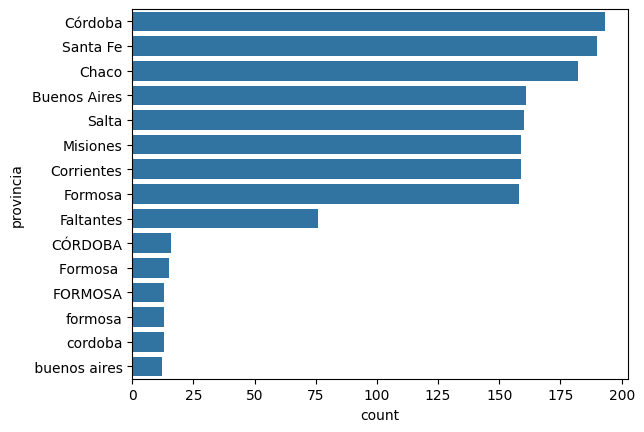

In [ ]:
provincia_grafico = df["provincia"].fillna("Faltantes")

sns.countplot(
    y=provincia_grafico, order=provincia_grafico.value_counts().index
)

In [ ]:
provincia_grafico.value_counts()

,count
provincia,
Córdoba,193
Santa Fe,190
Chaco,182
Buenos Aires,161
Salta,160
Misiones,159
Corrientes,159
Formosa,158
Faltantes,76


In [ ]:
df["categoria_preferida"].unique()

array(['Programación', 'Data Science', 'Ciberseguridad', 'Idiomas',
       'Diseño', 'Marketing', nan], dtype=object)

<Axes: xlabel='count', ylabel='categoria_preferida'>

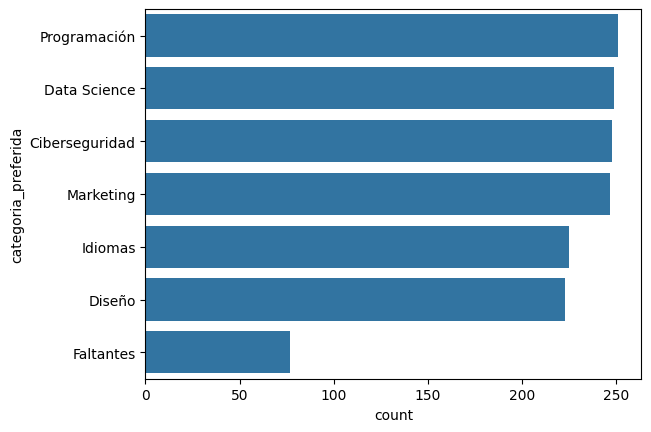

In [ ]:
categoria_grafico = df["categoria_preferida"].fillna("Faltantes")

sns.countplot(y=categoria_grafico, order= categoria_grafico.value_counts().index)

In [ ]:
categoria_grafico.value_counts()

,count
categoria_preferida,
Programación,251
Data Science,249
Ciberseguridad,248
Marketing,247
Idiomas,225
Diseño,223
Faltantes,77


In [ ]:
df["dispositivo_principal"].unique()

array(['Mobile', 'Tablet', 'Desktop'], dtype=object)

<Axes: xlabel='count', ylabel='dispositivo_principal'>

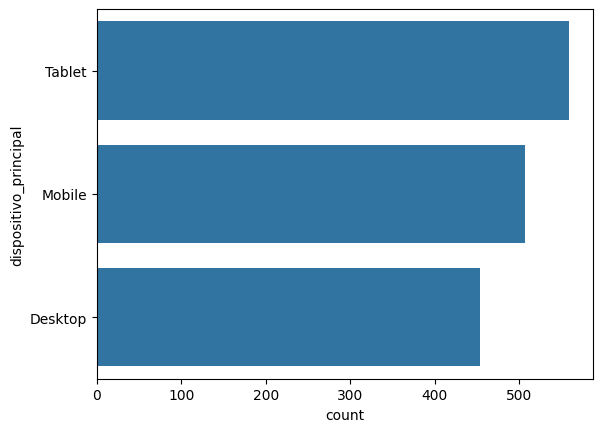

In [ ]:
sns.countplot(y=df["dispositivo_principal"], order=df["dispositivo_principal"]
              .value_counts().index)

In [ ]:
df["nivel_preferido"].unique()

array(['Avanzado', 'Principiante', 'Intermedio'], dtype=object)

<Axes: xlabel='count', ylabel='nivel_preferido'>

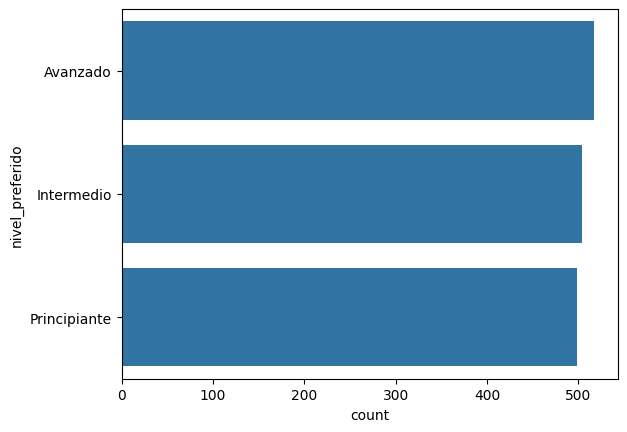

In [ ]:
sns.countplot(data=df, y="nivel_preferido", order=df["nivel_preferido"].value_counts().index)

## 6. Un mismo dato escrito de distintas maneras

Ahora, identifiquemos si existen valores con espacios sobrantes, mayúsculas, minúsculas, acentos y nombres equivalentes. La limpieza debe reducir categorías artificiales sin borrar diferencias reales.

In [ ]:
### Resuelto mas arriba

## 7. Analizando la distribución de edades

Preguntas guía:

- ¿Cuál es la edad promedio y la mediana?
- ¿Cuál es la edad mínima y máxima?
- ¿La distribución parece simétrica?
- ¿Existen valores extraños?



In [ ]:
display("La edad promedio es: ",df["edad"].mean())
display("La mediana de la edad es: ", df["edad"].median())

'La edad promedio es: '

np.float64(40.69757785467128)

'La mediana de la edad es: '

39.0

In [ ]:
df["edad"].describe()

,edad
count,1445.000000
mean,40.697578
std,18.637169
min,16.000000
25%,28.000000
50%,39.000000
75%,53.000000
max,200.000000


<Axes: xlabel='edad', ylabel='Count'>

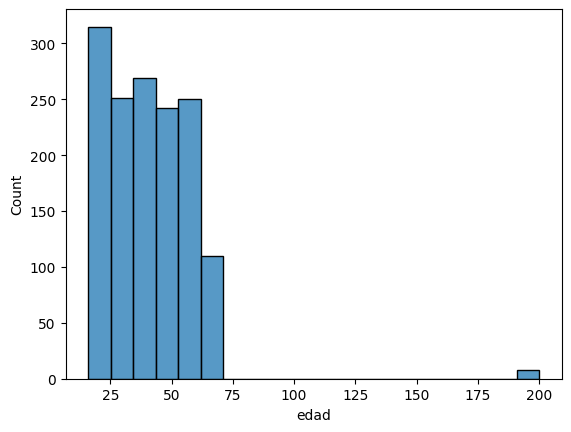

In [ ]:
sns.histplot(data=df, x="edad", bins=20)

La distribución de la variale Edad es Asimetrica Positiva


## 8. Detección de valores atípicos

También revisemos `horas_estudio_total` y `duracion_promedio_sesion_min`.

> Un valor atípico no siempre es un error. La pregunta no es “¿debo eliminarlo?”, sino “¿es posible y tiene sentido dentro del problema?”.

<Axes: xlabel='horas_estudio_total'>

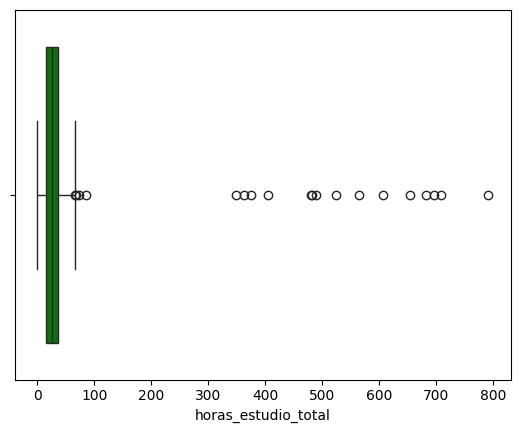

In [ ]:
sns.boxplot(data=df, x="horas_estudio_total", color="green")

<Axes: xlabel='duracion_promedio_sesion_min'>

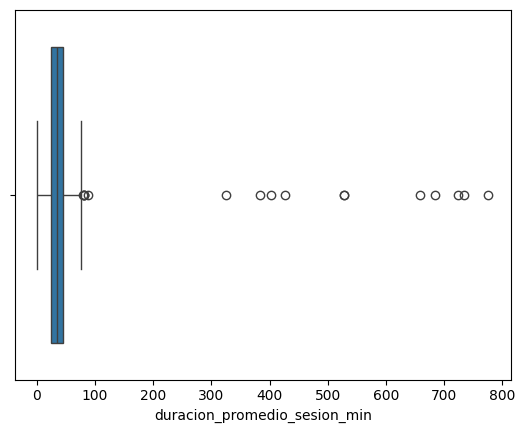

In [ ]:
sns.boxplot(data=df, x="duracion_promedio_sesion_min")

## 9. Comportamiento de las horas de estudio

Analicemos `horas_estudio_total`:

- ¿Dónde se concentra la mayoría?
- ¿La distribución es simétrica?
- ¿Hay usuarios con muchas más horas?
- ¿Es más representativa la media o la mediana?


Si hay valores extremos, la media puede desplazarse y la mediana puede ser más resistente.



<Axes: xlabel='horas_estudio_total', ylabel='Count'>

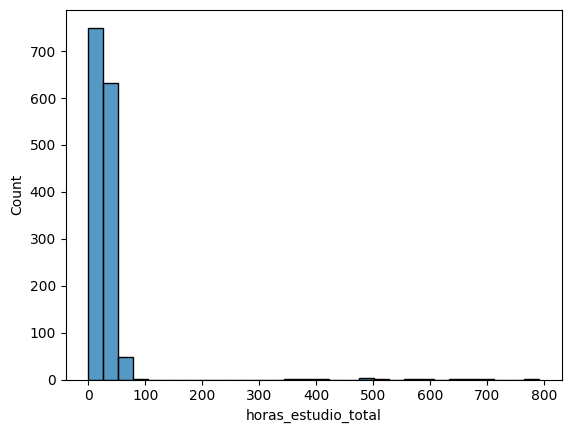

In [ ]:
sns.histplot(data=df, x="horas_estudio_total", bins=30)

La distribución de horas_estudio_total es asimetrica positiva. Existen valores extremos.

In [ ]:
df["horas_estudio_total"].median()

25.74

In [ ]:
df.columns

Index(['usuario_id', 'nombre', 'edad', 'provincia', 'categoria_preferida',
       'nivel_preferido', 'dispositivo_principal', 'fecha_registro',
       'ultima_actividad', 'horas_estudio_total', 'cursos_iniciados',
       'cursos_completados', 'sesiones_ultimo_mes',
       'duracion_promedio_sesion_min', 'evaluacion_promedio',
       'abandono_plataforma'],
      dtype='object')

## 10. Relación entre horas de estudio y cursos completados

> ¿Los usuarios que acumulan más horas de estudio tienden a completar más cursos?

```python
sns.scatterplot(
    data=df,
    x='hs',
    y='cs'
)
plt.show()
```

Observar una tendencia no demuestra causalidad. El gráfico sugiere una relación para investigar, pero no prueba que estudiar más sea la causa de completar más cursos.

<Axes: xlabel='horas_estudio_total', ylabel='cursos_completados'>

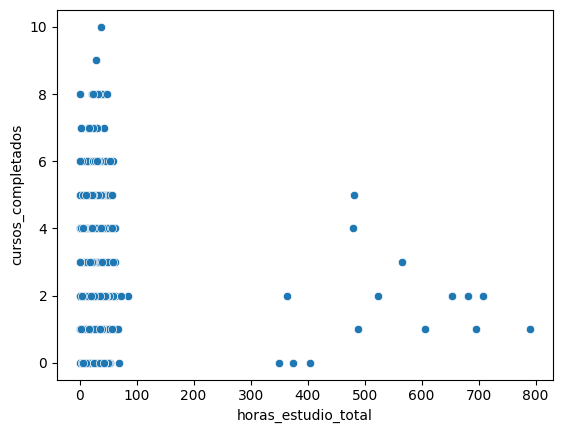

In [ ]:
sns.scatterplot(data=df, x="horas_estudio_total", y="cursos_completados")

## 11. Comparando grupos de usuarios

> ¿Existen diferencias en las horas de estudio según el dispositivo principal utilizado?

Preguntas:

- ¿Qué grupo tiene mayor mediana?
- ¿Cuál presenta más dispersión?
- ¿Hay valores atípicos?
- ¿Los tamaños de los grupos son parecidos?


In [ ]:
df.columns

Index(['usuario_id', 'nombre', 'edad', 'provincia', 'categoria_preferida',
       'nivel_preferido', 'dispositivo_principal', 'fecha_registro',
       'ultima_actividad', 'horas_estudio_total', 'cursos_iniciados',
       'cursos_completados', 'sesiones_ultimo_mes',
       'duracion_promedio_sesion_min', 'evaluacion_promedio',
       'abandono_plataforma'],
      dtype='object')

In [ ]:
df.groupby("dispositivo_principal")["horas_estudio_total"].median()

,horas_estudio_total
dispositivo_principal,
Desktop,24.640
Mobile,26.045
Tablet,26.185


<Axes: xlabel='dispositivo_principal', ylabel='horas_estudio_total'>

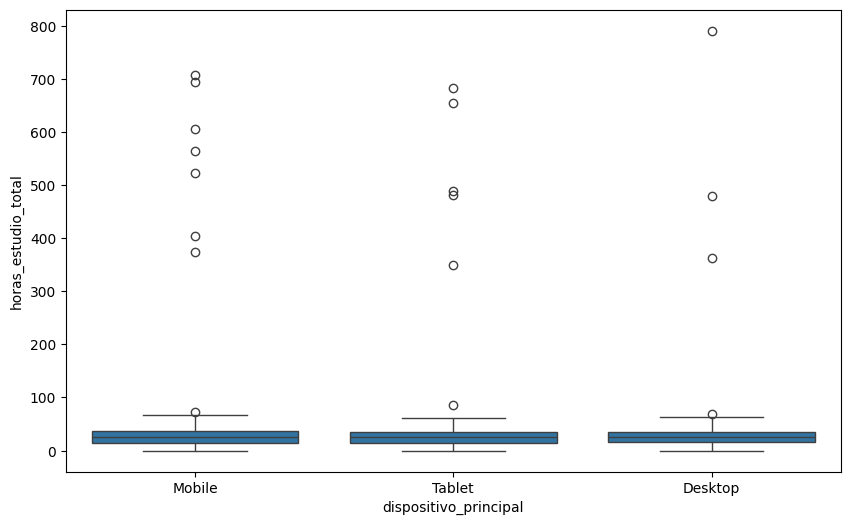

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x="dispositivo_principal",y="horas_estudio_total")

In [ ]:
df["dispositivo_principal"].value_counts(normalize=True) * 100

,proportion
dispositivo_principal,
Tablet,36.776316
Mobile,33.355263
Desktop,29.868421



## 12. Analizando el abandono de la plataforma

¿El dataset está equilibrado? ¿Qué diferencias aparecen entre quienes abandonaron y quienes permanecieron? Esto prepara la idea de una futura predicción, aunque todavía estamos haciendo análisis descriptivo.

<Axes: xlabel='abandono_plataforma', ylabel='count'>

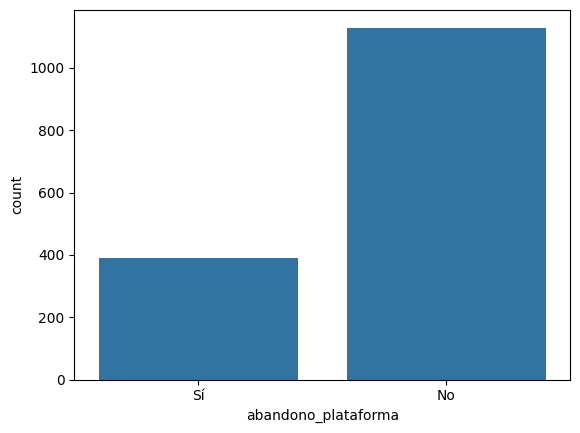

In [ ]:
sns.countplot(data=df, x="abandono_plataforma")

In [ ]:
df.columns

Index(['usuario_id', 'nombre', 'edad', 'provincia', 'categoria_preferida',
       'nivel_preferido', 'dispositivo_principal', 'fecha_registro',
       'ultima_actividad', 'horas_estudio_total', 'cursos_iniciados',
       'cursos_completados', 'sesiones_ultimo_mes',
       'duracion_promedio_sesion_min', 'evaluacion_promedio',
       'abandono_plataforma'],
      dtype='object')

In [ ]:
df.groupby("abandono_plataforma")[["horas_estudio_total",
                                  "sesiones_ultimo_mes",
                                  "cursos_completados",
                                  "evaluacion_promedio"]].median().round(2)

,horas_estudio_total,sesiones_ultimo_mes,cursos_completados,evaluacion_promedio
abandono_plataforma,,,,
No,25.43,12.0,2.0,7.04
Sí,26.43,12.0,2.0,7.00


In [ ]:
df.groupby("abandono_plataforma")["nivel_preferido"].value_counts()

abandono_plataforma  nivel_preferido
No                   Principiante       390
                     Avanzado           370
                     Intermedio         369
Sí                   Avanzado           147
                     Intermedio         135
                     Principiante       109
Name: count, dtype: int64

# Parte 2 — Transformación y limpieza de datos

Después de conocer los datos, podemos corregir problemas de calidad. Una transformación es útil si mejora la interpretación, la consistencia o el análisis posterior.

## 13. Conversión de fechas

`fecha_registro` y `ultima_actividad` representan fechas, aunque inicialmente estén almacenadas como texto.



In [ ]:
df_copia = df.copy()

In [ ]:
df_copia["fecha_registro"] = pd.to_datetime(df["fecha_registro"], format="mixed")

In [ ]:
df_copia["ultima_actividad"] = pd.to_datetime(df["ultima_actividad"], format="mixed")

## 14. Normalización de categorías

Una estrategia inicial para `provincia` consiste en eliminar espacios y unificar mayúsculas y minúsculas:

```python
df['provincia_limpia'] = (
    df['provincia']
    .str.strip()
    .str.lower()
)
```

El resultado puede requerir además una normalización de acentos y un diccionario de equivalencias. Verifiquemos el resultado:

```python
df['provincia_limpia'].value_counts(dropna=False)
```



In [ ]:
df_copia["provincia"] = df_copia["provincia"].str.upper().str.strip()

In [ ]:
df_copia["provincia"].unique()

array([nan, 'FORMOSA', 'CHACO', 'SANTA FE', 'CÓRDOBA', 'MISIONES',
       'BUENOS AIRES', 'SALTA', 'CORRIENTES', 'CORDOBA'], dtype=object)

In [ ]:
df_copia["provincia"] = df_copia["provincia"].replace({"CÓRDOBA": "CORDOBA"})

In [ ]:
df_copia["provincia"].unique()

array([nan, 'FORMOSA', 'CHACO', 'SANTA FE', 'CORDOBA', 'MISIONES',
       'BUENOS AIRES', 'SALTA', 'CORRIENTES'], dtype=object)

In [ ]:
df_copia["provincia"].mode()

,provincia
0,CORDOBA


In [ ]:
df_copia["provincia"] = df_copia["provincia"].fillna("CORDOBA")

## 15. Tratamiento de valores faltantes

No existe una única forma correcta. Podemos eliminar registros, reemplazar por una medida, crear `Desconocido`, mantener el faltante o imputar con información adicional.

### Debate por variable

¿Qué haríamos con `edad`, `provincia`, `categoria_preferida`, `horas_estudio_total` y `evaluacion_promedio`? Justificar cada decisión.

> Imputar no es “adivinar” sin consecuencias: modifica los datos y debe documentarse.

<Axes: xlabel='edad'>

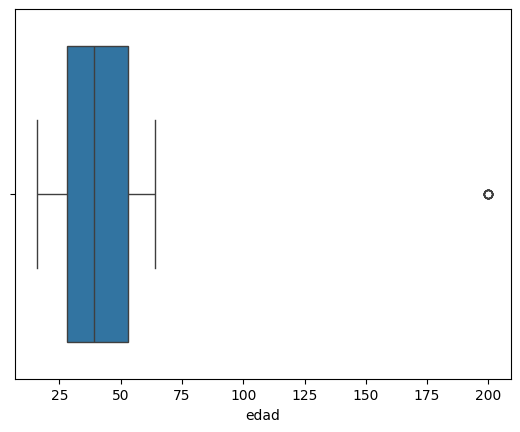

In [ ]:
sns.boxplot(data=df_copia, x="edad")

In [ ]:
mediana_edad = df_copia["edad"].median()
mediana_edad

39.0

In [ ]:
df_copia["edad"] = df_copia["edad"].fillna(mediana_edad)
df_copia["edad"].isnull().sum()


np.int64(0)

In [ ]:
df_copia["categoria_preferida"].isna().sum()
df_copia["categoria_preferida"].unique()

array(['Programación', 'Data Science', 'Ciberseguridad', 'Idiomas',
       'Diseño', 'Marketing', nan], dtype=object)

In [ ]:
df_copia["categoria_preferida"]= df_copia["categoria_preferida"].fillna("SIN DATOS")

<Axes: xlabel='horas_estudio_total'>

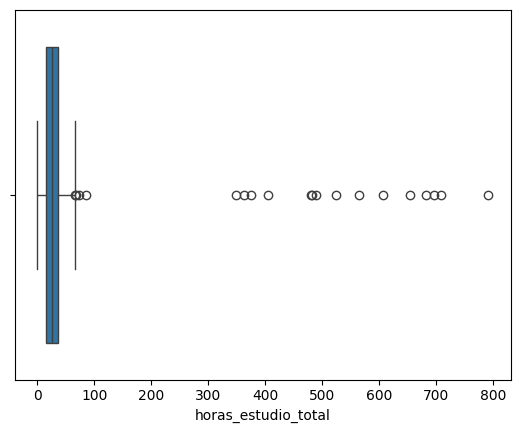

In [ ]:
sns.boxplot(data=df_copia, x="horas_estudio_total")

In [ ]:
df_copia["horas_estudio_total"].mean()

np.float64(30.90242906574394)

In [ ]:
df_copia["horas_estudio_total"] = df_copia["horas_estudio_total"].fillna(df_copia["horas_estudio_total"].median())

In [ ]:
df_copia["evaluacion_promedio"]  =df_copia["evaluacion_promedio"].fillna(df_copia["evaluacion_promedio"].mean())

In [ ]:
df_copia.isna().sum()

,0
usuario_id,0
nombre,0
edad,0
provincia,0
categoria_preferida,0
nivel_preferido,0
dispositivo_principal,0
fecha_registro,0
ultima_actividad,0
horas_estudio_total,0


### 16 Validaciones de errores:
Un dato puede no estar ausente y aun así ser incorrecto. Si el contexto establece que los usuarios tienen entre 16 y 100 años, podemos identificar edades inválidas:


El rango válido debe surgir del contexto, una regla del negocio o una fuente confiable.


In [ ]:

df_copia[df_copia["edad"] > 100]

,usuario_id,nombre,edad,provincia,categoria_preferida,nivel_preferido,dispositivo_principal,fecha_registro,ultima_actividad,horas_estudio_total,cursos_iniciados,cursos_completados,sesiones_ultimo_mes,duracion_promedio_sesion_min,evaluacion_promedio,abandono_plataforma
48,49,Florencia Arcos-Alcolea,200.0,FORMOSA,Ciberseguridad,Intermedio,Mobile,2026-03-18,2026-05-03,708.00,3,2,12,28.33,5.41,No
475,476,Ciriaco Plaza Polo,200.0,SANTA FE,Diseño,Intermedio,Tablet,2025-03-21,2025-09-20,31.17,3,2,12,36.61,7.24,No
563,564,Oriana Verdejo,200.0,CHACO,Marketing,Avanzado,Mobile,2023-09-14,2023-09-20,5.73,2,2,10,19.72,4.59,No
814,815,Apolonia Gilabert Olivares,200.0,SANTA FE,Ciberseguridad,Intermedio,Mobile,2024-11-18,2025-01-05,30.07,4,1,11,17.98,8.26,Sí
1004,1005,Febe Cortina Sureda,200.0,MISIONES,Data Science,Intermedio,Desktop,2025-02-23,2026-02-03,29.64,4,4,14,31.81,9.43,No
1125,1126,Heriberto Chico,200.0,FORMOSA,Marketing,Avanzado,Mobile,2026-05-01,2026-05-29,36.04,7,5,11,20.80,6.35,No
1194,1195,Atilio Sarabia Abril,200.0,CORRIENTES,SIN DATOS,Principiante,Desktop,2026-04-05,2026-08-21,31.69,2,2,9,52.56,6.51,No
1435,1436,Corona Céspedes Sevillano,200.0,SANTA FE,Diseño,Intermedio,Mobile,2024-07-01,2026-06-18,27.34,3,1,12,57.93,6.39,No


In [ ]:
index = df_copia[df_copia["edad"] > 100].index

In [ ]:
df_copia.loc[index, "edad"] = df_copia["edad"].median()

In [ ]:
df_copia["edad"] = df_copia["edad"].replace({"200": df_copia["edad"].median()})


In [ ]:
df_copia["edad"] = df_copia["edad"].astype("int")
df_copia["edad"]

/tmp/ipykernel_9664/1521459776.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_copia["edad"] = df_copia["edad"].astype("int")


,edad
0,54
1,39
2,18
3,51
4,33
...,...
1495,46
1496,40
1497,38
1498,30



## 17. Eliminación de duplicados

Si comprobamos que son duplicados exactos y no eventos distintos, podemos eliminarlos.


Eliminar duplicados cambia la cantidad de observaciones y puede cambiar las conclusiones. Toda limpieza importante debe poder explicarse.

In [ ]:
df_copia = df_copia.drop_duplicates()

# Parte 3 — Introducción a Feature Engineering

Una *feature* es una característica o variable que representa información sobre una observación. El objetivo no es crear columnas al azar: buscamos representar mejor un comportamiento relevante del problema.

## 18. Para persar:
A partir de las variables vistas en nuestro dataset, ¿Que nueva variable podemos crear?

In [ ]:
df_copia.columns

Index(['usuario_id', 'nombre', 'edad', 'provincia', 'categoria_preferida',
       'nivel_preferido', 'dispositivo_principal', 'fecha_registro',
       'ultima_actividad', 'horas_estudio_total', 'cursos_iniciados',
       'cursos_completados', 'sesiones_ultimo_mes',
       'duracion_promedio_sesion_min', 'evaluacion_promedio',
       'abandono_plataforma'],
      dtype='object')

In [ ]:
fecha_referencia = df_copia["ultima_actividad"].max()


In [ ]:
df_copia["antiguedad_dias"] = (
    fecha_referencia - df_copia["fecha_registro"]
).dt.days

/tmp/ipykernel_9664/1313414194.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_copia["antiguedad_dias"] = (


In [ ]:
df_copia["antiguedad_dias"]

,antiguedad_dias
0,448
1,275
2,780
3,895
4,149
...,...
1495,611
1496,876
1497,825
1498,174


In [ ]:
df_copia["tasa_finalizacion"] = (
    df_copia['cursos_completados'] / df_copia["cursos_iniciados"].replace(0, pd.NA)
)

/tmp/ipykernel_9664/1719435207.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_copia["tasa_finalizacion"] = (


In [ ]:
df_copia["tasa_finalizacion"]

,tasa_finalizacion
0,1.0
1,<NA>
2,0.25
3,0.75
4,1.0
...,...
1495,1.0
1496,0.3
1497,0.25
1498,0.333333


## ¿Por qué hacemos Feature Engineering?

Las variables originales no siempre representan directamente el fenómeno que queremos estudiar. `fecha_registro` puede ser menos útil que `antiguedad_dias`; `cursos_completados`, menos informativo que `tasa_finalizacion`. Feature Engineering transforma los datos para representar mejor la información relevante.

# Desafío integrador

Construyan un plan para analizar el abandono de la plataforma. Primero describan las decisiones; después implementen el código.

1. ¿Cuál sería la variable objetivo?
2. ¿Qué columnas excluirían por ser identificadores o texto no necesario?
3. ¿Qué problemas de calidad revisarían primero?
4. ¿Cómo tratarían faltantes, duplicados, categorías inconsistentes y edades inválidas?
5. ¿Qué dos features crearían?
6. ¿Qué gráfico usarían para comparar quienes abandonaron y quienes permanecieron?
7. ¿Qué conclusión no se puede afirmar solo con un gráfico descriptivo?

